# Trial Analysis for in house build linear regressor model

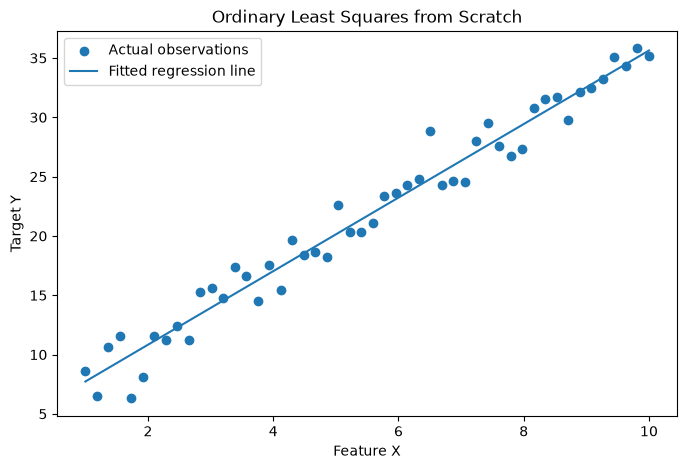

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

from linreg import MyLinearRegression

rng = np.random.default_rng(42)

X = np.linspace(1, 10, 50)

y = 5 + 3 * X + rng.normal(0, 2, size=50)

model = MyLinearRegression()
model.fit(X, y)

predictions = model.predict(X)

plt.figure(figsize=(8, 5))

plt.scatter(X, y, label="Actual observations")
plt.plot(X, predictions, label="Fitted regression line")

plt.xlabel("Feature X")
plt.ylabel("Target Y")
plt.title("Ordinary Least Squares from Scratch")
plt.legend()
plt.show()

Coefficient history shape: (6, 1)


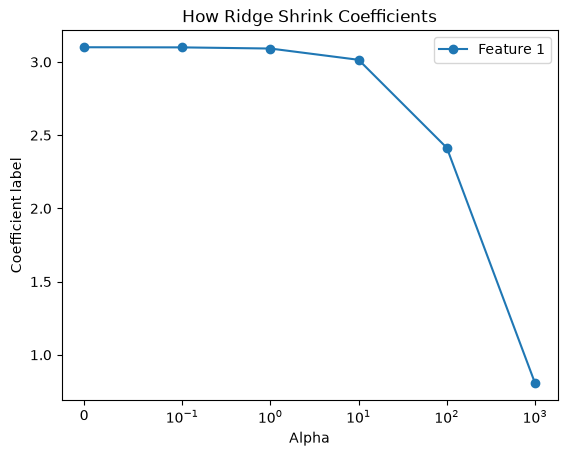

In [2]:
#Visualize OLS versus Ridge shrinkage

import matplotlib.pyplot as plt

alpha_values = [0, 0.1, 1, 10, 100, 1000]

coefficient_history = []

for alpha in alpha_values:

    model = MyLinearRegression(alpha=alpha, penalty='l2')
    model.fit(X, y)

    coefficient_history.append(model.coef_)

coefficient_history = np.array(coefficient_history)

print("Coefficient history shape:", coefficient_history.shape)


for j in range(coefficient_history.shape[1]):

    plt.plot(alpha_values, coefficient_history[:, j], marker="o", label=f"Feature {j + 1}")

plt.xscale("symlog", linthresh = 0.1)
plt.xlabel("Alpha")
plt.ylabel("Coefficient label")
plt.title("How Ridge Shrink Coefficients")
plt.legend()
plt.show()

In [3]:
values = [5, 3, 1, -1, -4]

for value in values:
    result = MyLinearRegression._soft_threshold(value, 2)
    print(value, "becomes", result)

5 becomes 3
3 becomes 1
1 becomes 0.0
-1 becomes -0.0
-4 becomes -2


In [4]:
#Test whether Lasso can eliminate features
rng = np.random.default_rng(42)

X_sparse = rng.normal(size=(200, 5))

true_weights = np.array([4, 0, 0, -3, 0])

y_sparse = (
    8
    + X_sparse @ true_weights
    + rng.normal(0, 0.3, size=200)
)

lasso_model = MyLinearRegression(
    alpha=0.2,
    penalty="l1"
)

lasso_model.fit(X_sparse, y_sparse)

print("True coefficients:", true_weights)
print("Estimated coefficients:", lasso_model.coef_)

print(
    "Number of zero coefficients:",
    np.sum(lasso_model.coef_ == 0)
)

True coefficients: [ 4  0  0 -3  0]
Estimated coefficients: [ 3.80912665  0.         -0.         -2.80406792 -0.        ]
Number of zero coefficients: 3


# Analysis on AB NY data

In [5]:
#Import the libraries
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

project_root = Path.cwd()

print(Path.cwd())

if project_root.name == "week05":
    project_root = project_root.parent

sys.path.insert(0, str(project_root / "week04"))

from pipeline import build_preprocessor

/Users/adilbegg/mlbatch1/week05


In [6]:
#Load dataset

data_path = (
    project_root
    / "week04"
    / "data"
    / "AB_NYC_2019.csv"
)

df = pd.read_csv(data_path)

print("Original dataset shape:", df.shape)

valid_rows = df["price"] > 0

X = df.loc[valid_rows].drop(
    columns="price"
)

y = df.loc[valid_rows, "price"]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Original dataset shape: (48895, 16)
Predictor shape: (48884, 15)
Target shape: (48884,)


In [7]:
#Divide the dataset into training and test sets

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

Training observations: 39107
Test observations: 9777


In [8]:
#Establish a mean-prediction baseline

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_train_r2 = baseline.score(X_train,y_train)

print("Baseline training R2:", baseline_train_r2)
print("Baseline prediction:", baseline.constant_[0, 0])

Baseline training R2: 0.0
Baseline prediction: 153.17907280026594


In [9]:
#Choose Ridge's alpha using cross-validation

ridge_pipeline = Pipeline([("pre", build_preprocessor()),("model", Ridge())])

alpha_options = { "model__alpha": [0.1, 1.0, 10.0, 100.0, 1000.0] }

cv = KFold(n_splits=5, shuffle=True, random_state=42)

search = GridSearchCV(estimator = ridge_pipeline, param_grid = alpha_options, scoring="r2", cv=cv, n_jobs=-1)

search.fit(X_train, y_train)

print("Best alpha:", search.best_params_)
print("Best CV R2:", search.best_score_)

Best alpha: {'model__alpha': 10.0}
Best CV R2: 0.1183148407993174


In [10]:
#Examine the alpha results

alpha_results = pd.DataFrame(search.cv_results_)

summary = alpha_results[["param_model__alpha", "mean_test_score", "std_test_score"]].copy()

summary.columns = ["Alpha", "Mean CV R2", "CV R2 Std"]

display(summary.round(4))

,Alpha,Mean CV R2,CV R2 Std
0,0.1,0.1178,0.0249
1,1.0,0.1179,0.0249
2,10.0,0.1183,0.0251
3,100.0,0.1182,0.0257
4,1000.0,0.1107,0.0249


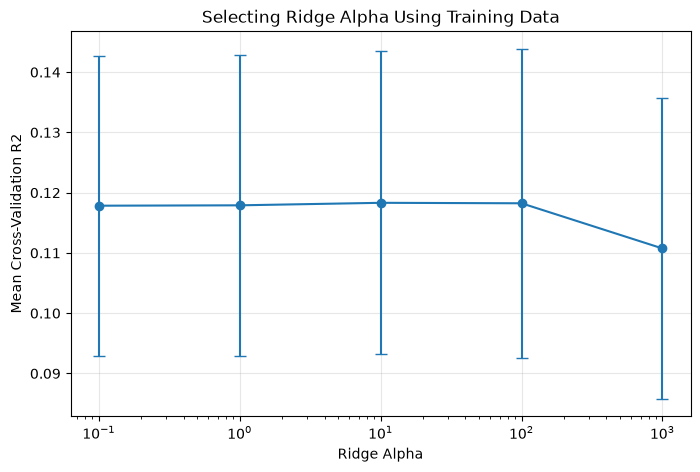

In [11]:
plt.figure(figsize=(8, 5))

plt.errorbar(
    summary["Alpha"],
    summary["Mean CV R2"],
    yerr=summary["CV R2 Std"],
    marker="o",
    capsize=4
)

plt.xscale("log")
plt.xlabel("Ridge Alpha")
plt.ylabel("Mean Cross-Validation R2")
plt.title("Selecting Ridge Alpha Using Training Data")
plt.grid(alpha=0.3)
plt.show()

In [12]:
#Calculate residuals without touching the test set

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error

# Best Ridge pipeline, selected using training CV
best_ridge = search.best_estimator_

# Predictions on training rows, made out-of-fold
oof_predictions = cross_val_predict(best_ridge, X_train, y_train, cv=cv, n_jobs=-1)

# Actual price minus predicted price
residuals = (y_train.to_numpy() - oof_predictions)

print("Number of residuals:", len(residuals))

print( "Out-of-fold R2:", r2_score(y_train, oof_predictions))

print( "Out-of-fold MAE:",mean_absolute_error(y_train, oof_predictions))

print("Mean residual:", np.mean(residuals))

print("Residual standard deviation:", np.std(residuals))

Number of residuals: 39107
Out-of-fold R2: 0.11111844245994507
Out-of-fold MAE: 72.33741815688191
Mean residual: 0.005372833360703808
Residual standard deviation: 234.9287017178213


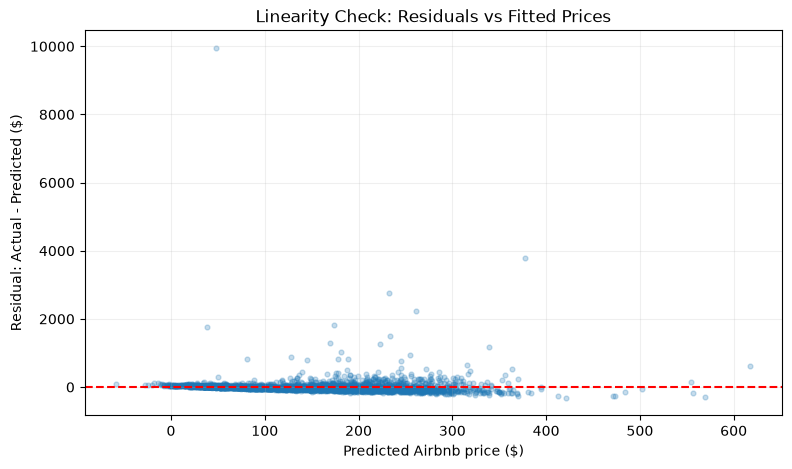

In [13]:
#Check Assumption 1: Linearity

rng = np.random.default_rng(42)

# Use a random subset to keep the graph readable
plot_indices = rng.choice(
    len(residuals),
    size=min(3000, len(residuals)),
    replace=False
)

plt.figure(figsize=(9, 5))

plt.scatter(
    oof_predictions[plot_indices],
    residuals[plot_indices],
    alpha=0.25,
    s=12
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Airbnb price ($)")
plt.ylabel("Residual: Actual - Predicted ($)")
plt.title("Linearity Check: Residuals vs Fitted Prices")
plt.grid(alpha=0.2)
plt.show()

,price_bin,mean_predicted,mean_residual,count
0,"(-58.28, 45.153]",25.286537,37.481298,3911
1,"(45.153, 72.058]",58.966439,13.931285,3911
2,"(72.058, 97.407]",84.467762,-7.153439,3910
3,"(97.407, 125.728]",111.748124,-13.304248,3911
4,"(125.728, 150.971]",138.483776,-15.566108,3911
5,"(150.971, 174.634]",163.146890,-12.394460,3910
6,"(174.634, 198.032]",185.963998,-19.027664,3911
7,"(198.032, 226.937]",212.135690,-17.854616,3910
8,"(226.937, 264.229]",244.395947,4.120545,3911
9,"(264.229, 625.886]",307.141896,29.811568,3911


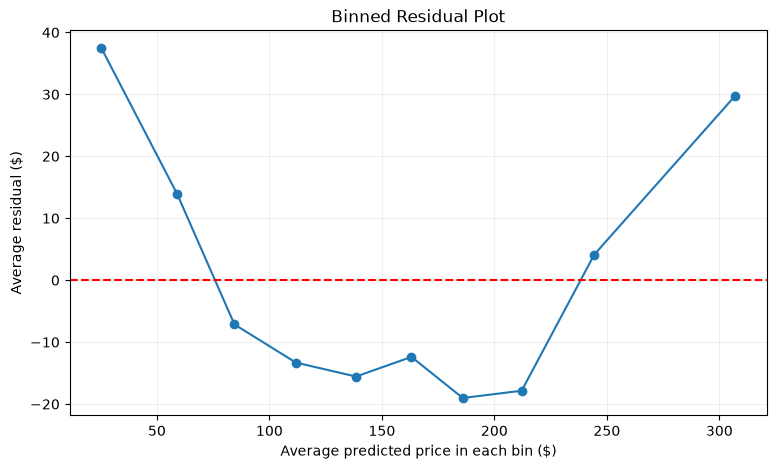

In [14]:
diagnostic_df = pd.DataFrame({
    "predicted_price": oof_predictions,
    "residual": residuals
})

diagnostic_df["price_bin"] = pd.qcut(
    diagnostic_df["predicted_price"],
    q=10,
    duplicates="drop"
)

linearity_summary = (
    diagnostic_df
    .groupby("price_bin", observed=True)
    .agg(
        mean_predicted=("predicted_price", "mean"),
        mean_residual=("residual", "mean"),
        count=("residual", "size")
    )
    .reset_index()
)

display(linearity_summary)

plt.figure(figsize=(9, 5))

plt.plot(
    linearity_summary["mean_predicted"],
    linearity_summary["mean_residual"],
    marker="o"
)

plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Average predicted price in each bin ($)")
plt.ylabel("Average residual ($)")
plt.title("Binned Residual Plot")
plt.grid(alpha=0.2)
plt.show()

In [15]:
#Check Assumption 2: Independence

from scipy import stats

independence_df = pd.DataFrame({
    "group": X_train["neighbourhood_group"].to_numpy(),
    "residual": residuals
})

group_summary = (
    independence_df
    .groupby("group")
    .agg(
        count=("residual", "size"),
        mean_residual=("residual", "mean"),
        median_residual=("residual", "median")
    )
    .sort_values("mean_residual")
)

display(group_summary)

groups = [
    group["residual"].to_numpy()
    for _, group in independence_df.groupby("group")
]

h_stat, p_value = stats.kruskal(*groups)

print("Kruskal-Wallis statistic:", h_stat)
print("P-value:", p_value)

,count,mean_residual,median_residual
group,,,
Staten Island,292,-3.779956,-29.779597
Queens,4546,-0.015235,-8.342247
Manhattan,17344,0.010748,-33.928881
Brooklyn,16059,0.058543,-13.794616
Bronx,866,0.296273,-8.735411


Kruskal-Wallis statistic: 963.6678452343331
P-value: 2.6667603445793938e-207


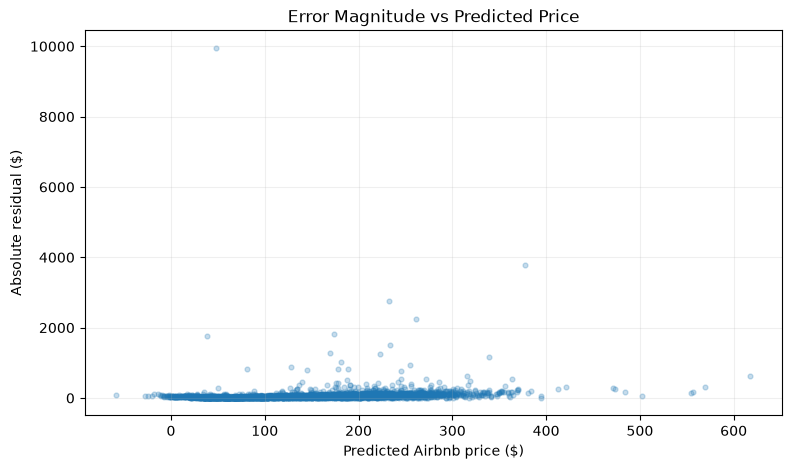

In [16]:
#Check Assumption 3: Homoscedasticity

plt.figure(figsize=(9, 5))

plt.scatter(
    oof_predictions[plot_indices],
    np.abs(residuals[plot_indices]),
    alpha=0.25,
    s=12
)

plt.xlabel("Predicted Airbnb price ($)")
plt.ylabel("Absolute residual ($)")
plt.title("Error Magnitude vs Predicted Price")
plt.grid(alpha=0.2)
plt.show()

In [17]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

# A constant and fitted price as variance predictors
variance_features = sm.add_constant(
    oof_predictions,
    has_constant="add"
)

bp_stat, bp_pvalue, bp_fstat, bp_f_pvalue = (
    het_breuschpagan(
        residuals,
        variance_features
    )
)

print("Breusch-Pagan LM statistic:", bp_stat)
print("Breusch-Pagan p-value:", bp_pvalue)
print("Breusch-Pagan F p-value:", bp_f_pvalue)

Breusch-Pagan LM statistic: 43.010113220132034
Breusch-Pagan p-value: 5.445762978658616e-11
Breusch-Pagan F p-value: 5.3878479956555357e-11


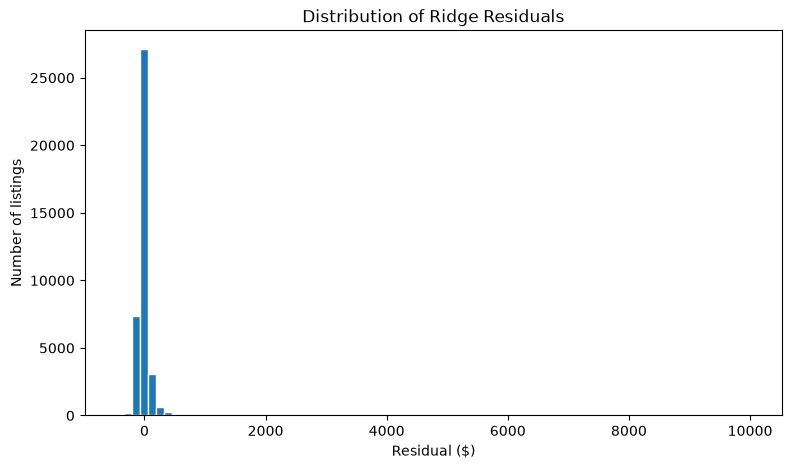

In [18]:
#Check Assumption 3: Normality

plt.figure(figsize=(9, 5))

plt.hist(
    residuals,
    bins=80,
    edgecolor="white"
)

plt.xlabel("Residual ($)")
plt.ylabel("Number of listings")
plt.title("Distribution of Ridge Residuals")
plt.show()


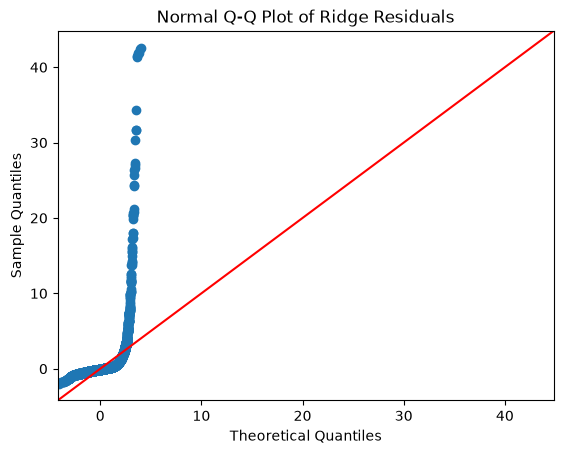

In [19]:
import statsmodels.api as sm

sm.qqplot(
    residuals,
    line="45",
    fit=True
)

plt.title("Normal Q-Q Plot of Ridge Residuals")
plt.show()

In [20]:
from scipy.stats import jarque_bera

jb_result = jarque_bera(residuals)

print(
    "Jarque-Bera statistic:",
    jb_result.statistic
)

print(
    "Jarque-Bera p-value:",
    jb_result.pvalue
)

print(
    "Residual skewness:",
    stats.skew(residuals)
)

print(
    "Residual excess kurtosis:",
    stats.kurtosis(residuals)
)

Jarque-Bera statistic: 873603485.1592863
Jarque-Bera p-value: 0.0
Residual skewness: 22.42243688426243
Residual excess kurtosis: 730.8352467499418


In [21]:
#Build the log-price regression model

from sklearn.compose import TransformedTargetRegressor

# Step 1: Build the normal Ridge pipeline
log_ridge_pipeline = Pipeline([
    ("pre", build_preprocessor()),
    ("model", Ridge(alpha=10.0))
])

# Step 2: Wrap it with a target transformation
log_ridge = TransformedTargetRegressor(
    regressor=log_ridge_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

print(log_ridge)
log_ridge

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('pre',
                                                      ColumnTransformer(transformers=[('standard',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(keep_empty_features=True,
                                                                                                                      strategy='median')),
                                                                                                       ('scaler',
                                                                                                        StandardScaler())]),
                                                                                       ['latitude',
                        

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...alpha=10.0))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indic

In [22]:
#Compare predictions using cross-validation

# Original Ridge out-of-fold predictions already exist:
# oof_predictions

# Generate out-of-fold predictions using log-price Ridge
log_oof_predictions = cross_val_predict(
    log_ridge,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1
)

# Calculate metrics for both models in dollars
comparison = pd.DataFrame({
    "Model": [
        "Original Ridge",
        "Log-price Ridge"
    ],
    "OOF R2": [
        r2_score(y_train, oof_predictions),
        r2_score(y_train, log_oof_predictions)
    ],
    "OOF MAE ($)": [
        mean_absolute_error(y_train, oof_predictions),
        mean_absolute_error(y_train, log_oof_predictions)
    ]
})

display(comparison.round(4))

,Model,OOF R2,OOF MAE ($)
0,Original Ridge,0.1111,72.3374
1,Log-price Ridge,0.1038,60.5950


In [23]:
#Check whether the modification changed the error patterns

# Original model's prediction errors
original_residuals = (
    y_train.to_numpy() - oof_predictions
)

# Log-price model's prediction errors, in dollars
log_dollar_residuals = (
    y_train.to_numpy() - log_oof_predictions
)

# Summary of prediction errors
error_summary = pd.DataFrame({
    "Model": [
        "Original Ridge",
        "Log-price Ridge"
    ],
    "Mean residual ($)": [
        np.mean(original_residuals),
        np.mean(log_dollar_residuals)
    ],
    "Median absolute error ($)": [
        np.median(np.abs(original_residuals)),
        np.median(np.abs(log_dollar_residuals))
    ],
    "Residual std ($)": [
        np.std(original_residuals),
        np.std(log_dollar_residuals)
    ]
})

display(error_summary.round(3))

,Model,Mean residual ($),Median absolute error ($),Residual std ($)
0,Original Ridge,0.005,43.269,234.929
1,Log-price Ridge,24.073,26.114,234.661


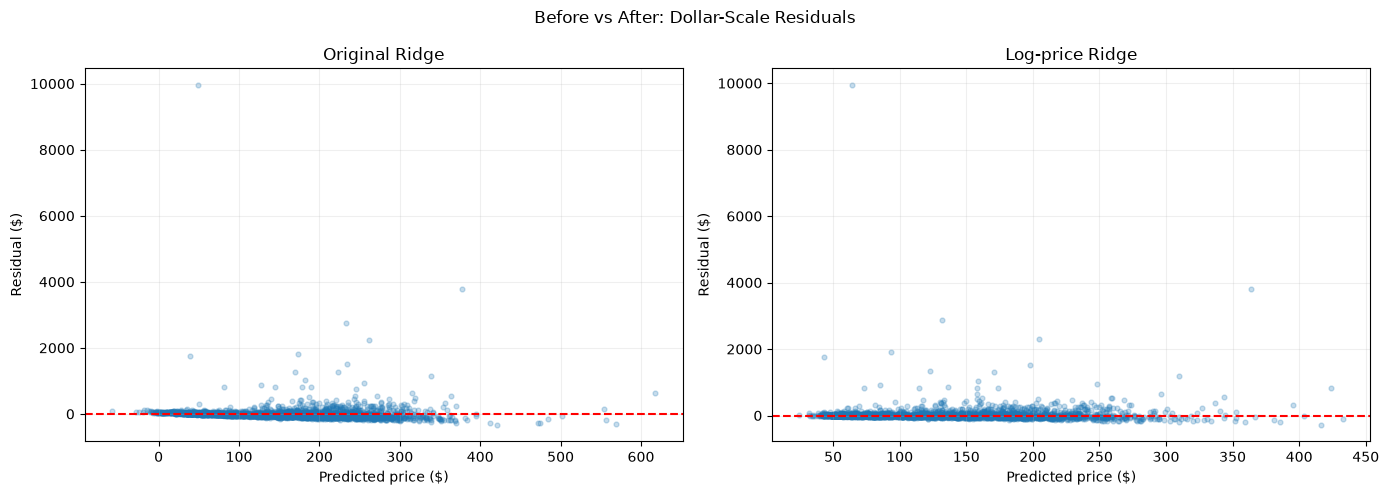

In [24]:
#Compare residual plots

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = [
    ("Original Ridge", oof_predictions, original_residuals),
    ("Log-price Ridge", log_oof_predictions, log_dollar_residuals)
]

for ax, (name, predictions, errors) in zip(axes, models):

    ax.scatter(
        predictions[plot_indices],
        errors[plot_indices],
        alpha=0.25,
        s=12
    )

    ax.axhline(
        0,
        color="red",
        linestyle="--"
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted price ($)")
    ax.set_ylabel("Residual ($)")
    ax.grid(alpha=0.2)

plt.suptitle("Before vs After: Dollar-Scale Residuals")
plt.tight_layout()
plt.show()

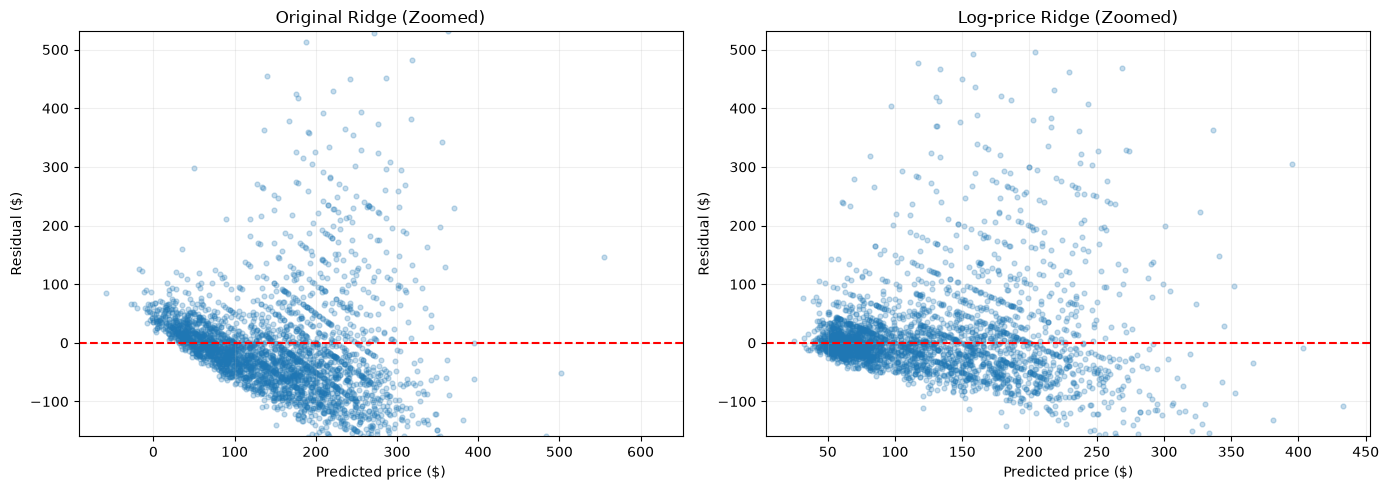

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Common vertical limits, based on both models
combined_errors = np.concatenate([
    original_residuals,
    log_dollar_residuals
])

lower_limit, upper_limit = np.percentile(
    combined_errors,
    [1, 99]
)

for ax, (name, predictions, errors) in zip(axes, models):

    ax.scatter(
        predictions[plot_indices],
        errors[plot_indices],
        alpha=0.25,
        s=12
    )

    ax.axhline(0, color="red", linestyle="--")
    ax.set_ylim(lower_limit, upper_limit)

    ax.set_title(name + " (Zoomed)")
    ax.set_xlabel("Predicted price ($)")
    ax.set_ylabel("Residual ($)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [26]:
#Recheck normality and homoscedasticity

# Convert actual and predicted prices to the log scale
actual_log_prices = np.log1p(
    y_train.to_numpy()
)

predicted_log_prices = np.log1p(
    log_oof_predictions
)

log_scale_residuals = (
    actual_log_prices - predicted_log_prices
)

# Normality diagnostics
jb_log = stats.jarque_bera(log_scale_residuals)

print("Log-scale Jarque-Bera statistic:", jb_log.statistic)
print("Log-scale Jarque-Bera p-value:", jb_log.pvalue)

print(
    "Log-scale skewness:",
    stats.skew(log_scale_residuals)
)

print(
    "Log-scale excess kurtosis:",
    stats.kurtosis(log_scale_residuals)
)

# Heteroscedasticity diagnostic
log_variance_features = sm.add_constant(
    predicted_log_prices,
    has_constant="add"
)

bp_log = het_breuschpagan(
    log_scale_residuals,
    log_variance_features
)

print("Log-scale BP statistic:", bp_log[0])
print("Log-scale BP p-value:", bp_log[1])

Log-scale Jarque-Bera statistic: 103071.70626069205
Log-scale Jarque-Bera p-value: 0.0
Log-scale skewness: 1.4058314322776644
Log-scale excess kurtosis: 7.439741120721758
Log-scale BP statistic: 174.2205477258657
Log-scale BP p-value: 8.859743115102237e-40


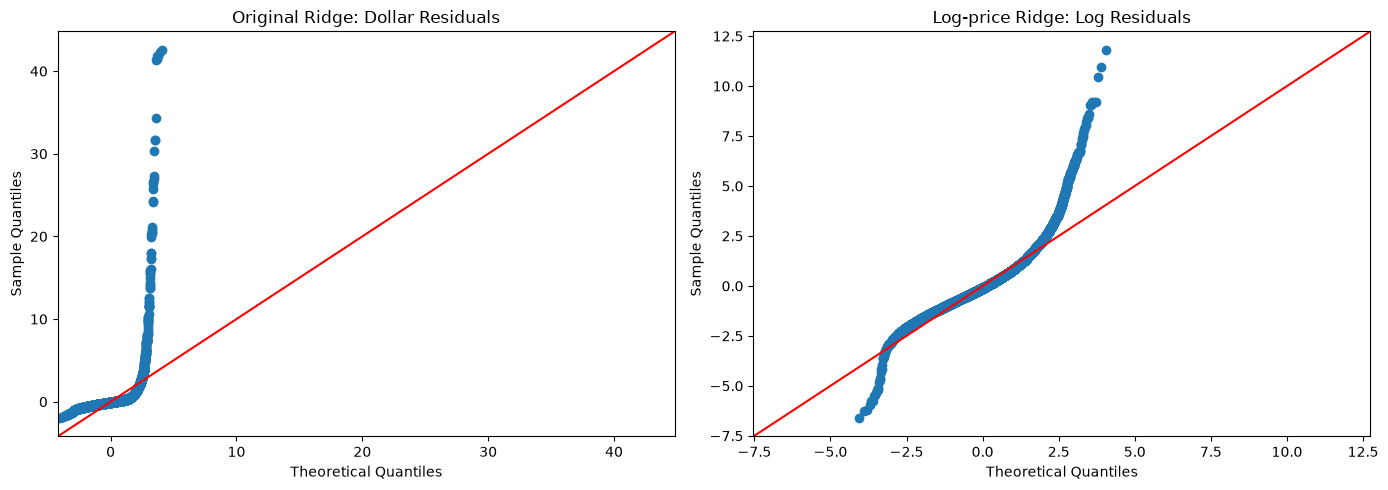

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sm.qqplot(
    original_residuals,
    line="45",
    fit=True,
    ax=axes[0]
)

axes[0].set_title("Original Ridge: Dollar Residuals")

sm.qqplot(
    log_scale_residuals,
    line="45",
    fit=True,
    ax=axes[1]
)

axes[1].set_title("Log-price Ridge: Log Residuals")

plt.tight_layout()
plt.show()

In [28]:
#Calculate corrected predictions safely

from sklearn.base import clone

# Empty arrays to store predictions
smearing_predictions = np.zeros(len(y_train))
smearing_factors = []

# The five folds already created earlier
for fold_number, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train),
    start=1
):

    # 1. Split the training data into two parts
    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    X_fold_val = X_train.iloc[val_idx]

    # 2. Create a fresh model for this fold
    fold_model = clone(log_ridge)

    # 3. Fit only on this fold's training rows
    fold_model.fit(X_fold_train, y_fold_train)

    # 4. Predict training rows on the log scale
    train_log_predictions = (
        fold_model.regressor_.predict(X_fold_train)
    )

    # 5. Calculate training residuals on log scale
    train_log_errors = (
        np.log1p(y_fold_train.to_numpy())
        - train_log_predictions
    )

    # 6. Calculate the smearing factor
    factor = np.mean(np.exp(train_log_errors))

    smearing_factors.append(factor)

    # 7. Predict unseen validation rows in dollars
    val_predictions = fold_model.predict(X_fold_val)

    # 8. Apply correction
    corrected_predictions = (
        factor * (val_predictions + 1) - 1
    )

    # Keep predictions nonnegative
    corrected_predictions = np.maximum(
        corrected_predictions, 0
    )

    # 9. Save predictions at their original positions
    smearing_predictions[val_idx] = corrected_predictions

    print(
        f"Fold {fold_number}: "
        f"Smearing factor = {factor:.4f}"
    )

Fold 1: Smearing factor = 1.1740
Fold 2: Smearing factor = 1.1762
Fold 3: Smearing factor = 1.1720
Fold 4: Smearing factor = 1.1642
Fold 5: Smearing factor = 1.1638


In [29]:
#Compare all three models

all_predictions = {
    "Original Ridge": oof_predictions,
    "Log-price Ridge": log_oof_predictions,
    "Log + Smearing": smearing_predictions
}

results = []

for name, predictions in all_predictions.items():

    errors = y_train.to_numpy() - predictions

    results.append({
        "Model": name,
        "OOF R2": r2_score(y_train, predictions),
        "OOF MAE ($)": mean_absolute_error(
            y_train, predictions
        ),
        "Mean residual ($)": np.mean(errors),
        "Median absolute error ($)": np.median(
            np.abs(errors)
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,OOF R2,OOF MAE ($),Mean residual ($),Median absolute error ($)
0,Original Ridge,0.1111,72.3374,0.0054,43.2686
1,Log-price Ridge,0.1038,60.5950,24.0732,26.1138
2,Log + Smearing,0.1180,66.4533,1.9471,34.4608


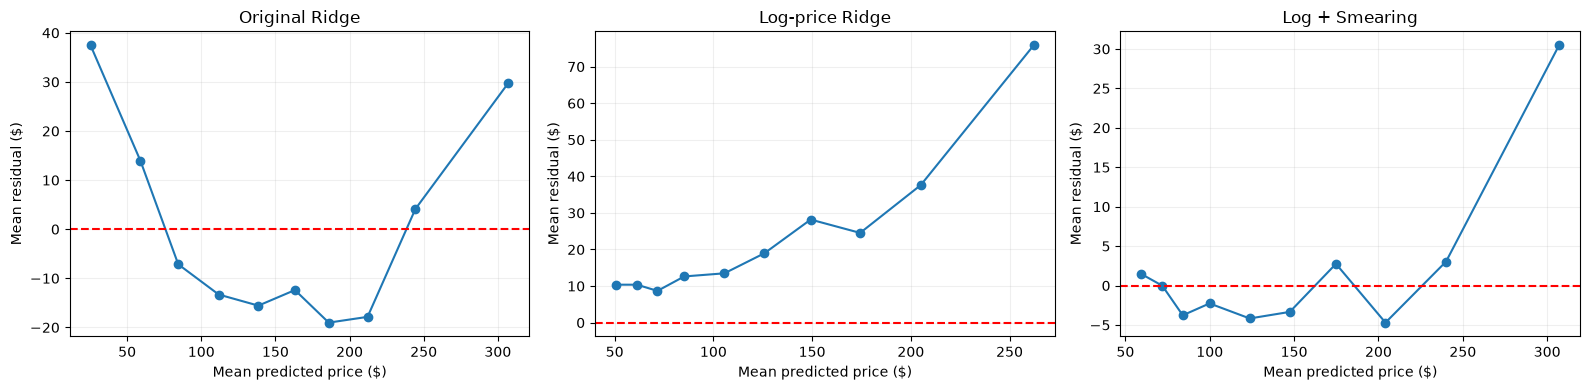

In [30]:
#Check whether the systematic bias has improved

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, predictions) in zip(
    axes,
    all_predictions.items()
):

    temp = pd.DataFrame({
        "prediction": predictions,
        "residual": y_train.to_numpy() - predictions
    })

    temp["bin"] = pd.qcut(
        temp["prediction"],
        q=10,
        duplicates="drop"
    )

    grouped = temp.groupby(
        "bin",
        observed=True
    ).agg(
        mean_prediction=("prediction", "mean"),
        mean_residual=("residual", "mean")
    )

    ax.plot(
        grouped["mean_prediction"],
        grouped["mean_residual"],
        marker="o"
    )

    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Mean predicted price ($)")
    ax.set_ylabel("Mean residual ($)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [31]:
# Candidate alpha values
alpha_candidates = [0.1, 1, 10, 100, 1000]

# Store each experiment's results
tuning_results = []

# Convert target to a NumPy array for easy indexing
y_array = y_train.to_numpy()

for alpha in alpha_candidates:

    # Store unseen-fold predictions
    predictions = np.zeros(len(y_train))

    for train_idx, val_idx in cv.split(X_train, y_train):

        X_fold_train = X_train.iloc[train_idx]
        y_fold_train = y_train.iloc[train_idx]

        X_fold_val = X_train.iloc[val_idx]

        # Create a new pipeline for this alpha
        inner_pipeline = Pipeline([
            ("pre", build_preprocessor()),
            ("model", Ridge(alpha=alpha))
        ])

        # Apply the logarithmic target transformation
        model = TransformedTargetRegressor(
            regressor=inner_pipeline,
            func=np.log1p,
            inverse_func=np.expm1
        )

        # Fit on this fold's training rows only
        model.fit(X_fold_train, y_fold_train)

        # Obtain log-scale predictions on training rows
        training_log_predictions = (
            model.regressor_.predict(X_fold_train)
        )

        # Calculate log-scale training errors
        training_log_errors = (
            np.log1p(y_fold_train.to_numpy())
            - training_log_predictions
        )

        # Learn smearing correction from training rows
        factor = np.mean(np.exp(training_log_errors))

        # Predict validation rows in dollars
        validation_predictions = model.predict(X_fold_val)

        # Apply smearing correction
        corrected_predictions = (
            factor * (validation_predictions + 1) - 1
        )

        # Avoid negative nightly price predictions
        corrected_predictions = np.maximum(
            corrected_predictions, 0
        )

        # Save validation predictions
        predictions[val_idx] = corrected_predictions

    # Evaluate all out-of-fold predictions
    tuning_results.append({
        "Alpha": alpha,
        "OOF R2": r2_score(y_array, predictions),
        "OOF MAE": mean_absolute_error(
            y_array, predictions
        ),
        "Mean residual": np.mean(
            y_array - predictions
        )
    })

# Display the results
tuning_df = pd.DataFrame(tuning_results)

display(tuning_df.round(4))

,Alpha,OOF R2,OOF MAE,Mean residual
0,0.1,0.1185,66.4963,1.7806
1,1.0,0.1184,66.4905,1.7983
2,10.0,0.1180,66.4533,1.9471
3,100.0,0.1149,66.4457,2.7102
4,1000.0,0.1046,67.0744,4.7988


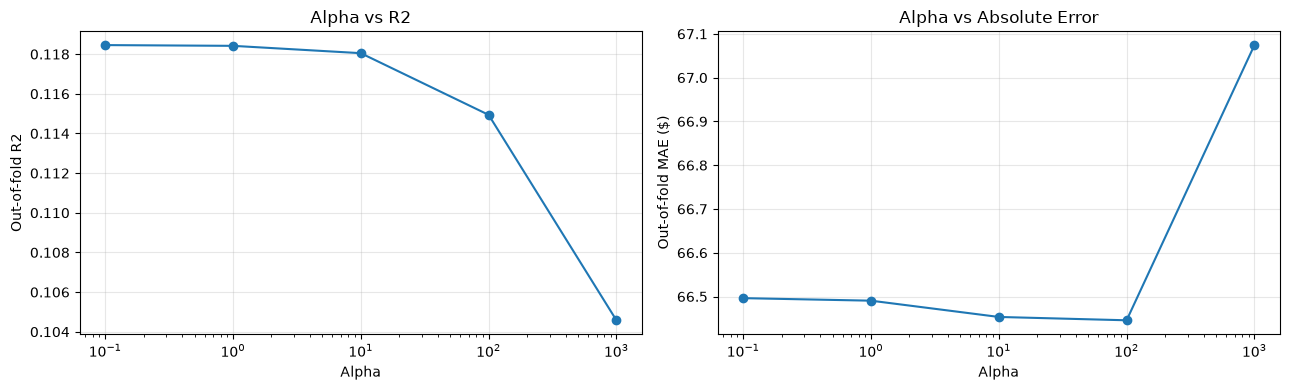

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Plot R2
axes[0].plot(
    tuning_df["Alpha"],
    tuning_df["OOF R2"],
    marker="o"
)

axes[0].set_xscale("log")
axes[0].set_xlabel("Alpha")
axes[0].set_ylabel("Out-of-fold R2")
axes[0].set_title("Alpha vs R2")
axes[0].grid(alpha=0.3)

# Plot MAE
axes[1].plot(
    tuning_df["Alpha"],
    tuning_df["OOF MAE"],
    marker="o"
)

axes[1].set_xscale("log")
axes[1].set_xlabel("Alpha")
axes[1].set_ylabel("Out-of-fold MAE ($)")
axes[1].set_title("Alpha vs Absolute Error")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
# Stage 17: Final model training

selected_alpha = 0.1

final_pipeline = Pipeline([
    ("pre", build_preprocessor()),
    ("model", Ridge(alpha=selected_alpha))
])

final_model = TransformedTargetRegressor(
    regressor=final_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

# Fit using ALL training observations
final_model.fit(X_train, y_train)

print("Final model fitted successfully.")
print("Selected alpha:", selected_alpha)
print("Training observations:", len(X_train))

Final model fitted successfully.
Selected alpha: 0.1
Training observations: 39107


In [34]:
# Predictions on the log scale for training observations
final_train_log_predictions = (
    final_model.regressor_.predict(X_train)
)

# Actual training prices on the log scale
actual_train_log_prices = np.log1p(
    y_train.to_numpy()
)

# Log-scale training errors
final_train_log_errors = (
    actual_train_log_prices
    - final_train_log_predictions
)

# Final smearing factor
final_smearing_factor = np.mean(
    np.exp(final_train_log_errors)
)

print(
    "Final smearing factor:",
    final_smearing_factor
)

Final smearing factor: 1.1694586946211147


In [35]:
def predict_with_smearing(model, X, factor):

    # Obtain predictions in dollar units
    predictions = model.predict(X)

    # Apply the smearing correction
    corrected = factor * (predictions + 1) - 1

    # Prevent negative price predictions
    corrected = np.maximum(corrected, 0)

    return corrected

In [36]:
#calculate training performance

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Training predictions with smearing correction
final_train_predictions = predict_with_smearing(
    final_model,
    X_train,
    final_smearing_factor
)

# Training metrics
train_r2 = r2_score(
    y_train,
    final_train_predictions
)

train_mae = mean_absolute_error(
    y_train,
    final_train_predictions
)

train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        final_train_predictions
    )
)

print("Training R2:", train_r2)
print("Training MAE:", train_mae)
print("Training RMSE:", train_rmse)

Training R2: 0.12059071345586325
Training MAE: 66.24379592417063
Training RMSE: 233.6736028581537


In [37]:
# FINAL HELD-OUT EVALUATION
# Do not change model selection based on these results.

# Predict unseen test observations
final_test_predictions = predict_with_smearing(
    final_model,
    X_test,
    final_smearing_factor
)

# Mean-price baseline trained on training data
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_test_predictions = baseline.predict(X_test)

# Final test R2
test_r2 = r2_score(
    y_test,
    final_test_predictions
)

# Final test MAE
test_mae = mean_absolute_error(
    y_test,
    final_test_predictions
)

# Final test RMSE
test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_test_predictions
    )
)

# Baseline test results
baseline_test_r2 = r2_score(
    y_test,
    baseline_test_predictions
)

baseline_test_mae = mean_absolute_error(
    y_test,
    baseline_test_predictions
)

print("Final test R2:", test_r2)
print("Final test MAE:", test_mae)
print("Final test RMSE:", test_rmse)

print("Baseline test R2:", baseline_test_r2)
print("Baseline test MAE:", baseline_test_mae)

Final test R2: 0.15239880665790995
Final test MAE: 65.49882151553068
Final test RMSE: 184.2132413413925
Baseline test R2: -0.00011226511882944656
Baseline test MAE: 91.2817637912871


In [38]:
final_performance = pd.DataFrame({
    "Evaluation": [
        "Mean baseline: Train",
        "Mean baseline: Test",
        "Final model: Train",
        "Final model: CV (OOF)",
        "Final model: Test"
    ],
    "R2": [
        baseline_train_r2,
        baseline_test_r2,
        train_r2,
        0.1185,  # Replace with the full-precision tuned CV result
        test_r2
    ],
    "MAE ($)": [
        mean_absolute_error(
            y_train,
            baseline.predict(X_train)
        ),
        baseline_test_mae,
        train_mae,
        np.nan,
        test_mae
    ]
})

display(final_performance.round(4))

,Evaluation,R2,MAE ($)
0,Mean baseline: Train,0.0000,92.9508
1,Mean baseline: Test,-0.0001,91.2818
2,Final model: Train,0.1206,66.2438
3,Final model: CV (OOF),0.1185,NaN
4,Final model: Test,0.1524,65.4988


In [39]:
selected_row = tuning_df.loc[
    tuning_df["Alpha"] == selected_alpha
].iloc[0]

final_performance.loc[
    final_performance["Evaluation"] == "Final model: CV (OOF)",
    "R2"
] = selected_row["OOF R2"]

final_performance.loc[
    final_performance["Evaluation"] == "Final model: CV (OOF)",
    "MAE ($)"
] = selected_row["OOF MAE"]

display(final_performance.round(4))

,Evaluation,R2,MAE ($)
0,Mean baseline: Train,0.0000,92.9508
1,Mean baseline: Test,-0.0001,91.2818
2,Final model: Train,0.1206,66.2438
3,Final model: CV (OOF),0.1185,66.4963
4,Final model: Test,0.1524,65.4988


In [40]:
# Get the fitted preprocessing pipeline
fitted_pipeline = final_model.regressor_

# Get the fitted Ridge regression model
fitted_ridge = fitted_pipeline.named_steps["model"]

# Get the fitted preprocessor
fitted_preprocessor = fitted_pipeline.named_steps["pre"]

# Extract the learned coefficients
coefficients = fitted_ridge.coef_

print("Number of coefficients:", len(coefficients))
print("Intercept:", fitted_ridge.intercept_)
print("First 10 coefficients:", coefficients[:10])

Number of coefficients: 105
Intercept: 4.163399737687689
First 10 coefficients: [ 0.02124929 -0.09256837 -0.09471377 -0.03167463 -0.01101319  0.33830478
 -0.00670889  0.03997426 -0.13324073  0.06510256]


In [41]:
try:
    feature_names = (
        fitted_preprocessor.get_feature_names_out()
    )

except (AttributeError, ValueError) as error:
    print("Feature-name extraction failed:", error)
    feature_names = None

if feature_names is not None:

    print("Number of feature names:", len(feature_names))
    print("Number of coefficients:", len(coefficients))

    assert len(feature_names) == len(coefficients)

    print("\nFirst 15 feature names:")

    for name in feature_names[:15]:
        print(name)

Number of feature names: 105
Number of coefficients: 105

First 15 feature names:
standard__latitude
standard__longitude
log__minimum_nights
log__number_of_reviews
robust__calculated_host_listings_count
availability__availability_365
reviews__reviews_per_month
reviews__missingindicator_reviews_per_month
low_card__neighbourhood_group_Bronx
low_card__neighbourhood_group_Brooklyn
low_card__neighbourhood_group_Manhattan
low_card__neighbourhood_group_Queens
low_card__neighbourhood_group_Staten Island
low_card__room_type_Entire home/apt
low_card__room_type_Private room


In [42]:
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Calculate coefficient magnitude
coefficient_table["Absolute coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

# Sort from largest magnitude to smallest
coefficient_table = (
    coefficient_table
    .sort_values(
        "Absolute coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

display(coefficient_table.head(20))

,Feature,Coefficient,Absolute coefficient
0,low_card__room_type_Entire home/apt,0.615381,0.615381
1,high_card__neighbourhood_Tribeca,0.586959,0.586959
2,low_card__room_type_Shared room,-0.501390,0.501390
3,low_card__neighbourhood_group_Staten Island,-0.478261,0.478261
4,high_card__neighbourhood_Inwood,-0.427951,0.427951
5,high_card__neighbourhood_Washington Heights,-0.420586,0.420586
6,high_card__neighbourhood_Corona,-0.418863,0.418863
7,high_card__neighbourhood_Bensonhurst,-0.408828,0.408828
8,high_card__neighbourhood_Borough Park,-0.385119,0.385119
9,low_card__neighbourhood_group_Manhattan,0.374235,0.374235


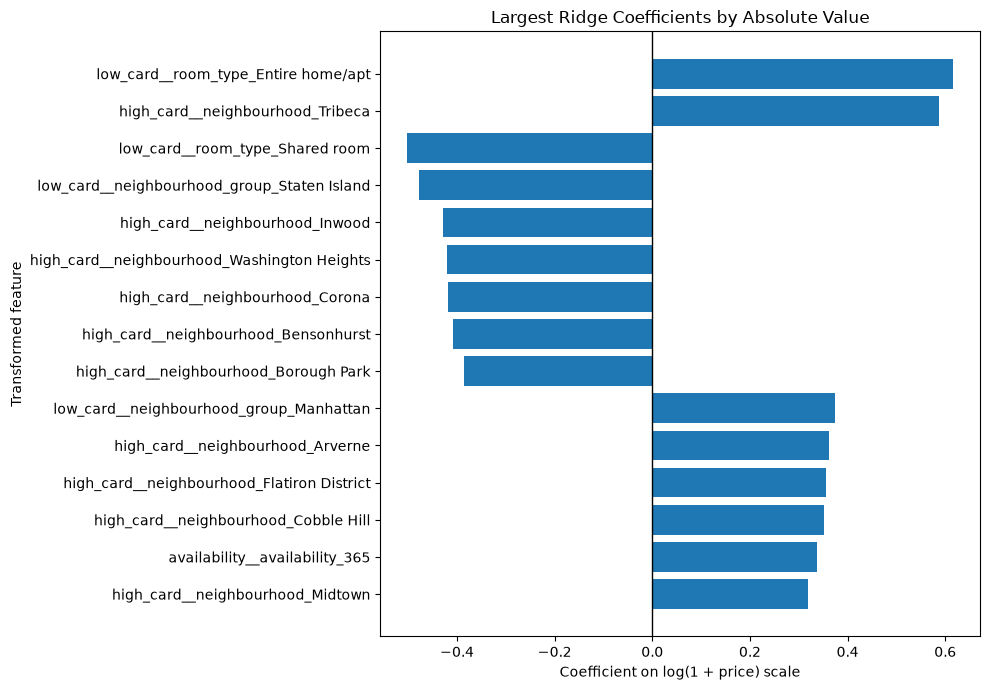

In [43]:
top_coefficients = coefficient_table.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_coefficients["Feature"],
    top_coefficients["Coefficient"]
)

plt.axvline(
    0,
    color="black",
    linewidth=1
)

plt.xlabel("Coefficient on log(1 + price) scale")
plt.ylabel("Transformed feature")
plt.title("Largest Ridge Coefficients by Absolute Value")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [44]:
room_coefficients = coefficient_table[
    coefficient_table["Feature"].str.contains(
        "low_card__room_type_",
        regex=False
    )
].copy()

display(
    room_coefficients[
        ["Feature", "Coefficient"]
    ]
)

,Feature,Coefficient
0,low_card__room_type_Entire home/apt,0.615381
2,low_card__room_type_Shared room,-0.501390
62,low_card__room_type_Private room,-0.113991


In [45]:
room_lookup = dict(
    zip(
        room_coefficients["Feature"],
        room_coefficients["Coefficient"]
    )
)

entire_beta = room_lookup[
    "low_card__room_type_Entire home/apt"
]

private_beta = room_lookup[
    "low_card__room_type_Private room"
]

difference = entire_beta - private_beta

percentage_difference = (
    np.exp(difference) - 1
) * 100

print("Coefficient difference:", difference)

print(
    "Entire home vs Private room:",
    f"{percentage_difference:.2f}%"
)

Coefficient difference: 0.7293727899059426
Entire home vs Private room: 107.38%


In [46]:
numeric_features = [
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

# Use training observations only
X_numeric = X_train[numeric_features].copy()

print("Numeric feature matrix shape:", X_numeric.shape)

print(
    "Missing values by feature:"
)

print(X_numeric.isna().sum())

Numeric feature matrix shape: (39107, 7)
Missing values by feature:
latitude                             0
longitude                            0
minimum_nights                       0
number_of_reviews                    0
reviews_per_month                 8012
calculated_host_listings_count       0
availability_365                     0
dtype: int64


In [47]:
from sklearn.impute import SimpleImputer

vif_imputer = SimpleImputer(
    strategy="median"
)

X_numeric_clean = vif_imputer.fit_transform(
    X_numeric
)

X_numeric_clean = pd.DataFrame(
    X_numeric_clean,
    columns=numeric_features,
    index=X_numeric.index
)

print(
    "Remaining missing values:",
    X_numeric_clean.isna().sum().sum()
)

Remaining missing values: 0


In [48]:
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

# Add an intercept column for auxiliary regressions
X_vif = sm.add_constant(
    X_numeric_clean,
    has_constant="add"
)

vif_results = []

for j, feature in enumerate(X_vif.columns):

    if feature == "const":
        continue

    vif_value = variance_inflation_factor(
        X_vif.to_numpy(),
        j
    )

    vif_results.append({
        "Feature": feature,
        "VIF": vif_value
    })

vif_table = pd.DataFrame(vif_results)

vif_table = vif_table.sort_values(
    "VIF",
    ascending=False
)

display(vif_table)

,Feature,VIF
4,reviews_per_month,1.511487
3,number_of_reviews,1.498158
6,availability_365,1.136332
5,calculated_host_listings_count,1.094731
1,longitude,1.053726
2,minimum_nights,1.051637
0,latitude,1.009741


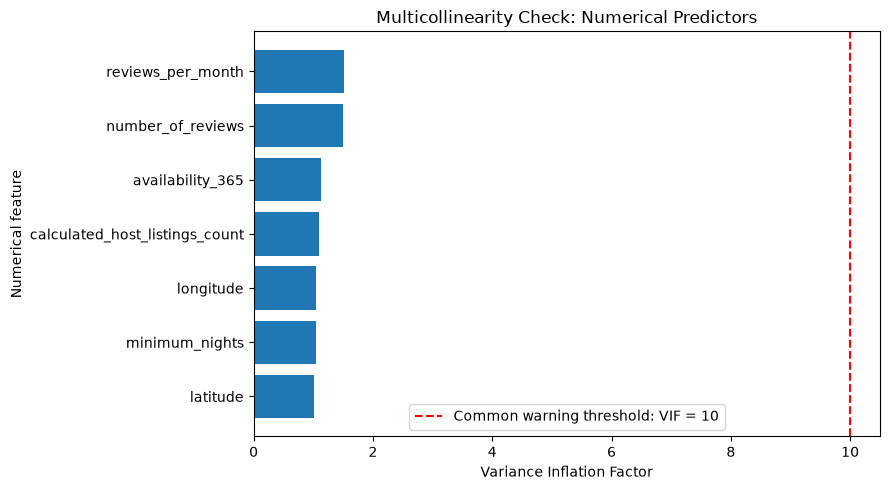

In [49]:
plt.figure(figsize=(9, 5))

plt.barh(
    vif_table["Feature"],
    vif_table["VIF"]
)

plt.axvline(
    10,
    color="red",
    linestyle="--",
    label="Common warning threshold: VIF = 10"
)

plt.xlabel("Variance Inflation Factor")
plt.ylabel("Numerical feature")
plt.title("Multicollinearity Check: Numerical Predictors")

plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [50]:
#Fit Lasso model on training dataset

from sklearn.linear_model import Lasso

lasso_pipeline = Pipeline([
    ("pre", build_preprocessor()),
    ("model", Lasso(
        alpha=0.01,
        max_iter=20000,
        tol=1e-5,
        selection="cyclic"
    ))
])

lasso_model = TransformedTargetRegressor(
    regressor=lasso_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

lasso_model.fit(X_train, y_train)

print("Lasso fitted successfully.")

Lasso fitted successfully.


In [51]:
# Extract the fitted Lasso estimator
fitted_lasso = (
    lasso_model
    .regressor_
    .named_steps["model"]
)

# Get its coefficients
lasso_coefficients = fitted_lasso.coef_

# Count coefficients equal to zero
zero_count = np.sum(lasso_coefficients == 0)

# Count nonzero coefficients
nonzero_count = np.sum(lasso_coefficients != 0)

print("Total features:", len(lasso_coefficients))
print("Zero coefficients:", zero_count)
print("Nonzero coefficients:", nonzero_count)
print("Lasso iterations:", fitted_lasso.n_iter_)

Total features: 105
Zero coefficients: 96
Nonzero coefficients: 9
Lasso iterations: 10


In [52]:
ridge_names = (
    fitted_preprocessor.get_feature_names_out()
)

lasso_names = (
    lasso_model
    .regressor_
    .named_steps["pre"]
    .get_feature_names_out()
)

ridge_table = pd.DataFrame({
    "Feature": ridge_names,
    "Ridge": fitted_ridge.coef_
})

lasso_table = pd.DataFrame({
    "Feature": lasso_names,
    "Lasso": lasso_coefficients
})

coefficient_comparison = ridge_table.merge(
    lasso_table,
    on="Feature",
    how="inner",
    validate="one_to_one"
)

assert len(coefficient_comparison) == len(ridge_names)
assert len(coefficient_comparison) == len(lasso_names)

coefficient_comparison["Ridge magnitude"] = (
    coefficient_comparison["Ridge"].abs()
)

coefficient_comparison = (
    coefficient_comparison
    .sort_values(
        "Ridge magnitude",
        ascending=False
    )
)

display(coefficient_comparison.head(20))

,Feature,Ridge,Lasso,Ridge magnitude
13,low_card__room_type_Entire home/apt,0.615381,0.761443,0.615381
94,high_card__neighbourhood_Tribeca,0.586959,0.000000,0.586959
15,low_card__room_type_Shared room,-0.501390,-0.000000,0.501390
12,low_card__neighbourhood_group_Staten Island,-0.478261,-0.000000,0.478261
60,high_card__neighbourhood_Inwood,-0.427951,-0.000000,0.427951
98,high_card__neighbourhood_Washington Heights,-0.420586,-0.000000,0.420586
34,high_card__neighbourhood_Corona,-0.418863,-0.000000,0.418863
21,high_card__neighbourhood_Bensonhurst,-0.408828,-0.000000,0.408828
23,high_card__neighbourhood_Borough Park,-0.385119,-0.000000,0.385119
10,low_card__neighbourhood_group_Manhattan,0.374235,0.252505,0.374235


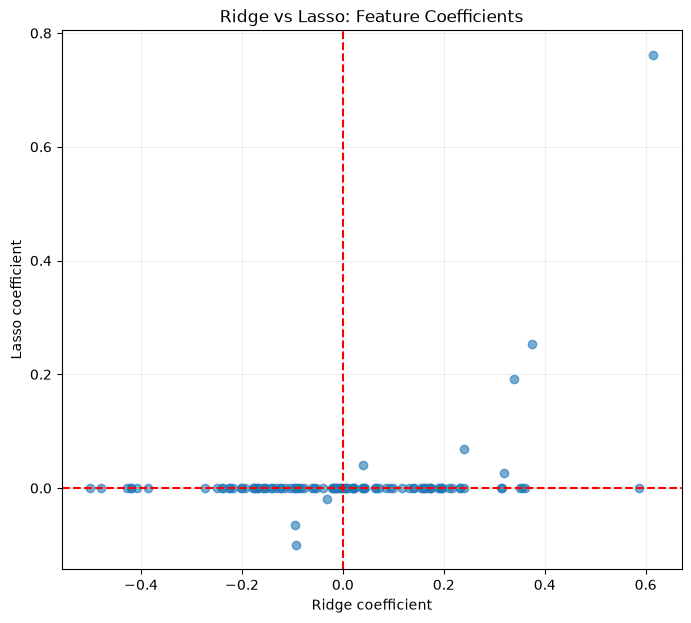

In [53]:
plt.figure(figsize=(8, 7))

plt.scatter(
    coefficient_comparison["Ridge"],
    coefficient_comparison["Lasso"],
    alpha=0.6
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Ridge coefficient")
plt.ylabel("Lasso coefficient")
plt.title("Ridge vs Lasso: Feature Coefficients")

plt.grid(alpha=0.2)
plt.show()

In [54]:
removed_features = coefficient_comparison[
    coefficient_comparison["Lasso"] == 0
]

print(
    "Number of features removed by Lasso:",
    len(removed_features)
)

display(
    removed_features[
        ["Feature", "Ridge", "Lasso"]
    ].head(25)
)

Number of features removed by Lasso: 96


,Feature,Ridge,Lasso
94,high_card__neighbourhood_Tribeca,0.586959,0.0
15,low_card__room_type_Shared room,-0.501390,-0.0
12,low_card__neighbourhood_group_Staten Island,-0.478261,-0.0
60,high_card__neighbourhood_Inwood,-0.427951,-0.0
98,high_card__neighbourhood_Washington Heights,-0.420586,-0.0
34,high_card__neighbourhood_Corona,-0.418863,-0.0
21,high_card__neighbourhood_Bensonhurst,-0.408828,-0.0
23,high_card__neighbourhood_Borough Park,-0.385119,-0.0
16,high_card__neighbourhood_Arverne,0.361075,0.0
47,high_card__neighbourhood_Flatiron District,0.355096,0.0


In [55]:
# Ridge predictions already include smearing correction
ridge_train_pred = final_train_predictions

# Lasso predictions converted back to dollars
lasso_train_pred = lasso_model.predict(X_train)

training_comparison = pd.DataFrame({
    "Model": [
        "Ridge + smearing",
        "Lasso without smearing"
    ],
    "Training R2": [
        r2_score(y_train, ridge_train_pred),
        r2_score(y_train, lasso_train_pred)
    ],
    "Training MAE ($)": [
        mean_absolute_error(
            y_train,
            ridge_train_pred
        ),
        mean_absolute_error(
            y_train,
            lasso_train_pred
        )
    ]
})

display(training_comparison.round(4))

,Model,Training R2,Training MAE ($)
0,Ridge + smearing,0.1206,66.2438
1,Lasso without smearing,0.0786,62.9819


In [56]:
# Select the features Lasso retained
selected_features = coefficient_comparison[
    coefficient_comparison["Lasso"] != 0
].copy()

# Sort by the size of the Lasso coefficient
selected_features["Lasso magnitude"] = (
    selected_features["Lasso"].abs()
)

selected_features = selected_features.sort_values(
    "Lasso magnitude",
    ascending=False
)

# Display the retained features
display(
    selected_features[
        ["Feature", "Ridge", "Lasso"]
    ]
)

print(
    "Number of retained features:",
    len(selected_features)
)

assert len(selected_features) == 9

,Feature,Ridge,Lasso
13,low_card__room_type_Entire home/apt,0.615381,0.761443
10,low_card__neighbourhood_group_Manhattan,0.374235,0.252505
5,availability__availability_365,0.338305,0.192336
1,standard__longitude,-0.092568,-0.100099
100,high_card__neighbourhood_Williamsburg,0.239324,0.068598
2,log__minimum_nights,-0.094714,-0.064272
7,reviews__missingindicator_reviews_per_month,0.039974,0.040291
71,high_card__neighbourhood_Midtown,0.319012,0.025763
3,log__number_of_reviews,-0.031675,-0.019650


Number of retained features: 9


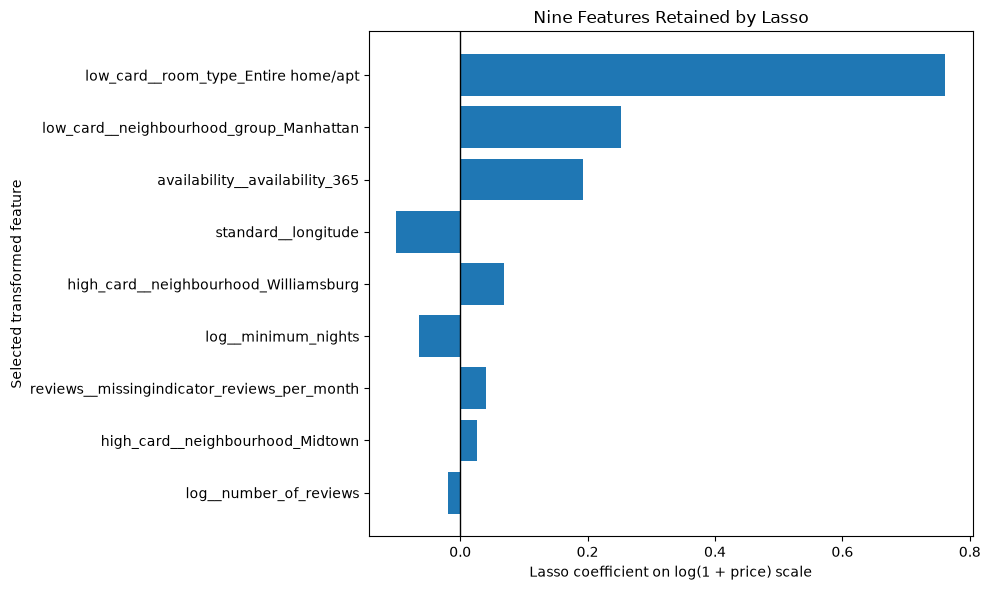

In [57]:
plt.figure(figsize=(10, 6))

plt.barh(
    selected_features["Feature"],
    selected_features["Lasso"]
)

plt.axvline(
    0,
    color="black",
    linewidth=1
)

plt.xlabel("Lasso coefficient on log(1 + price) scale")
plt.ylabel("Selected transformed feature")
plt.title("Nine Features Retained by Lasso")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [58]:
from pathlib import Path

# Find the Week 05 directory
week05_dir = project_root / "week05"

# Create a folder for analytical outputs
output_dir = week05_dir / "outputs"

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Save our coefficient tables
coefficient_comparison.to_csv(
    output_dir / "ridge_lasso_coefficients.csv",
    index=False
)

selected_features.to_csv(
    output_dir / "lasso_selected_features.csv",
    index=False
)

vif_table.to_csv(
    output_dir / "numerical_vif.csv",
    index=False
)

final_performance.to_csv(
    output_dir / "model_performance.csv",
    index=False
)

print("Saved analytical tables to:", output_dir)

Saved analytical tables to: /Users/adilbegg/mlbatch1/week05/outputs
